# 06_restoration_benchmark.ipynb

Task 4.4. Đánh giá các kỹ thuật khử nhiễu và phục hồi độ nét: Gaussian, median, bilateral, non-local means (NLM) và unsharp mask, trên bảy họ suy giảm của benchmark 4.1. Model là reference model Swin-Tiny đóng băng, không train lại.

Chỉ dùng tập validation. Tập test không được mở, tham số chốt ở đây rồi mới sang task 4.5.

Khử nhiễu áp cho `noise`, `sensor_noise`, `lowlight`. Làm nét áp cho `blur`, `motion_blur`, `lowres`. `jpeg` không có kỹ thuật phù hợp nên làm điều kiện đối chứng cho mọi kỹ thuật. Các họ còn lại chạy cấu hình chung của kỹ thuật làm đối chứng không phù hợp.

Notebook làm năm việc, cùng khuôn với notebook 05: kiểm tra ảnh suy giảm khớp với 4.1, tối ưu tham số từng kỹ thuật trên các họ phù hợp, chọn cấu hình, chạy đối chứng, và đo chi phí trên ảnh sạch. Bộ lọc OpenCV chạy song song bằng luồng trên CPU, model chạy trên GPU.

## 1. Môi trường

Internet để On. Accelerator chọn GPU (T4). Dataset input cần hai cái: `cthng123/durian-leaf-disease-dataset` và dataset chứa checkpoint `swin_tiny_seed42.pt` (cùng dataset đã dùng cho notebook 03, 04 và 05).

In [1]:
import os
import subprocess
import sys
from pathlib import Path

# Đổi nhánh tại đây, rồi chạy lại cell.
GIT_BRANCH = "restoration-benchmark"
REPO_URL = "https://github.com/meo225/durian-leaf-disease-robustness.git"
REPO_DIR = Path("/kaggle/working") / "durian-leaf-disease-robustness"

if not (Path("/kaggle/working").is_dir() and Path("/kaggle/input").is_dir()):
    raise RuntimeError("Notebook này chỉ chạy trên Kaggle. Xem README, mục Chạy trên Kaggle.")

def git(args, cwd=None):
    subprocess.run(
        ["git", *args],
        cwd=cwd,
        check=True,
        env={**os.environ, "GIT_TERMINAL_PROMPT": "0"},
    )


if not (REPO_DIR / ".git").is_dir():
    git(["clone", "--branch", GIT_BRANCH, "--single-branch", REPO_URL, str(REPO_DIR)])
else:
    git(["fetch", "origin", GIT_BRANCH], cwd=REPO_DIR)
    git(["checkout", GIT_BRANCH], cwd=REPO_DIR)
    git(["reset", "--hard", f"origin/{GIT_BRANCH}"], cwd=REPO_DIR)

matches = []
seen = set()
for path in Path("/kaggle/input").rglob("DLD_FinalDataset_224_spit"):
    resolved = str(path.resolve())
    if path.is_dir() and resolved not in seen:
        seen.add(resolved)
        matches.append(path)

if not matches:
    found = []
    input_root = Path("/kaggle/input")
    if input_root.is_dir():
        for path in sorted(input_root.rglob("*")):
            if path.is_dir() and len(path.relative_to(input_root).parts) <= 3:
                found.append(str(path.relative_to(input_root)))
    listing = "\n".join(found[:40]) if found else "(trống)"
    raise FileNotFoundError(
        "Chưa thấy DLD_FinalDataset_224_spit trong /kaggle/input.\n"
        "Add Input: cthng123/durian-leaf-disease-dataset, rồi Save & Run All.\n"
        f"Thư mục hiện có:\n{listing}"
    )

image_root = matches[0].parent
link = REPO_DIR / "datasets" / "durian-ldd"
link.parent.mkdir(parents=True, exist_ok=True)
if link.is_symlink() or link.is_file():
    link.unlink()
elif link.exists():
    link.rmdir()
link.symlink_to(image_root, target_is_directory=True)

if not (link / "DLD_FinalDataset_224_spit").is_dir():
    raise FileNotFoundError(f"Không thấy ảnh tại {link}")

os.chdir(REPO_DIR)
if str(REPO_DIR) not in sys.path:
    sys.path.insert(0, str(REPO_DIR))

commit = subprocess.check_output(
    ["git", "rev-parse", "--short", "HEAD"], cwd=REPO_DIR, text=True
).strip()
branch = subprocess.check_output(
    ["git", "branch", "--show-current"], cwd=REPO_DIR, text=True
).strip()
print(f"Nhánh: {branch}")
print(f"Commit: {commit}")
print(f"Ảnh: {link / 'DLD_FinalDataset_224_spit'}")

Cloning into '/kaggle/working/durian-leaf-disease-robustness'...


Nhánh: restoration-benchmark
Commit: 2fa3d40
Ảnh: /kaggle/working/durian-leaf-disease-robustness/datasets/durian-ldd/DLD_FinalDataset_224_spit


## 2. Checkpoint và dữ liệu

Nạp reference model, tạo 21 điều kiện suy giảm của scope task này trên 444 ảnh validation, lưu dạng uint8. Mọi cấu hình xử lý chạy lên chính các ảnh này.

In [2]:
import json
import os
import time

import cv2

import numpy as np
import pandas as pd
import torch
import yaml
from IPython.display import Image, display
from torch import nn

from src.corruption import build_loader, load_conditions, load_seed
from src.evaluation import plot_corruption_examples
from src.evaluation.processing_benchmark import (
    ImageCache, Runner, best_per_condition, build_matrix, clean_cost_table, example_grid, load_grid,
    make_processor, run_clean_cost, run_controls, run_tuning, save_predictions, scope_conditions, select_configs,
)
from src.evaluation.processing_plots import (
    plot_best_per_condition, plot_clean_cost, plot_confusion_cases, plot_grid_search, plot_matrix_heatmap, plot_rank_table,
)
from src.evaluation.reference import collect_checkpoint, load_trained_model
from src.training.loop import evaluate_loader, resolve_device

FIG = REPO_DIR / "outputs/figures/restoration"
RES = REPO_DIR / "outputs/results/restoration"
REP = REPO_DIR / "reports/processing"
for folder in (FIG, RES, REP):
    folder.mkdir(parents=True, exist_ok=True)


# Bộ lọc OpenCV giải phóng GIL nên chạy song song bằng luồng. Mỗi luồng dùng một nhân để khỏi tranh nhau.
WORKERS = max(1, min(8, os.cpu_count() or 1))
cv2.setNumThreads(1)
print(f"Số luồng lọc ảnh: {WORKERS}")


def show(path):
    display(Image(filename=str(path)))


grid_cfg = load_grid("configs/restoration.yaml")
pipeline_cfg = yaml.safe_load((REPO_DIR / "configs/pipeline.yaml").read_text(encoding="utf-8"))
classes = list(pipeline_cfg["classes"])
reference = json.loads((REPO_DIR / "reports/baselines/reference_final.json").read_text(encoding="utf-8"))["selection"]["reference"]
assert reference == "swin_tiny", f"Reference model là {reference}, notebook này viết cho swin_tiny."
train_cfg = yaml.safe_load((REPO_DIR / "configs/train_swin_tiny.yaml").read_text(encoding="utf-8"))

checkpoint = collect_checkpoint("/kaggle/input", grid_cfg["checkpoint_name"], "/kaggle/working/checkpoints")
device = resolve_device()
model = load_trained_model(train_cfg, checkpoint, len(classes), device)
print(f"Reference model: {reference}, thiết bị: {device}")

seed = load_seed(grid_cfg["corruption_config"])
conditions = scope_conditions(load_conditions(grid_cfg["corruption_config"], "val"), grid_cfg["scope_families"])
families = list(grid_cfg["scope_families"])
print(f"{len(conditions)} điều kiện thuộc {len(families)} họ: {', '.join(families)}")

start = time.time()
cache = ImageCache(pipeline_cfg, conditions, seed)
for name in ["clean", *conditions]:
    cache.get(name)
print(f"{len(cache)} ảnh validation, {len(conditions) + 1} bộ ảnh uint8, mất {time.time() - start:.0f} giây")

Số luồng lọc ảnh: 4
Reference model: convnext_tiny, thiết bị: cuda
21 điều kiện thuộc 7 họ: noise, sensor_noise, lowlight, blur, motion_blur, lowres, jpeg
444 ảnh validation, 22 bộ ảnh uint8, mất 90 giây


### Kiểm tra khớp với benchmark 4.1

Ảnh suy giảm ở đây được tạo một lần rồi dùng lại, khác đường đi của loader ở 4.1. Ô dưới so điểm "không xử lý" của ba điều kiện giữa hai đường đi. Hai số phải trùng nhau, nếu lệch thì dừng.

In [3]:
runner = Runner(model, cache, pipeline_cfg, device, progress=print, workers=WORKERS)
criterion = nn.CrossEntropyLoss()
for name in ["noise_s2", "motion_blur_s3", "jpeg_s1"]:
    expected = evaluate_loader(model, build_loader(pipeline_cfg, "val", name, conditions[name], seed), criterion, device, classes)["macro_f1"]
    runner.run("raw", "none", "none", None, name)
    mine = runner.rows[-1]["macro_f1"]
    print(f"{name:16s} loader 4.1: {expected:.6f}   cache: {mine:.6f}")
    assert abs(mine - expected) < 1e-6, "Ảnh suy giảm không khớp pipeline 4.1"
print("Khớp.")

noise_s2         loader 4.1: 0.849377   cache: 0.849377
motion_blur_s3   loader 4.1: 0.634870   cache: 0.634870
jpeg_s1          loader 4.1: 0.896008   cache: 0.896008
Khớp.


## 3. Minh họa trực quan các kỹ thuật

Chưa tối ưu gì. Mỗi họ suy giảm (dòng) qua các kỹ thuật với một cấu hình mặc định (cột): ảnh sạch, ảnh suy giảm, rồi kết quả xử lý. Xem kỹ thuật nào sửa đúng loại hỏng, kỹ thuật nào làm ảnh xấu hơn hoặc mất vết bệnh.

Ảnh 0 (ALGAL_LEAF_SPOT), mức 2


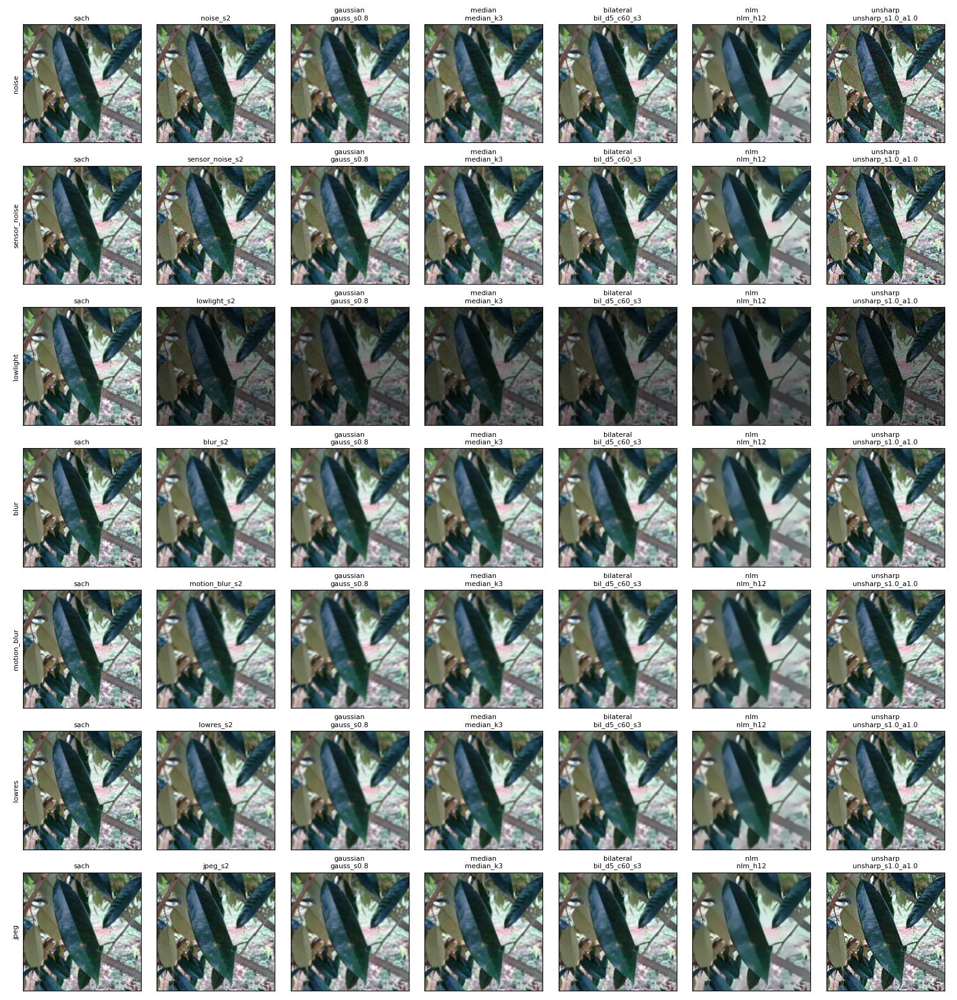

Ảnh 57 (LEAF_BLIGHT), mức 3


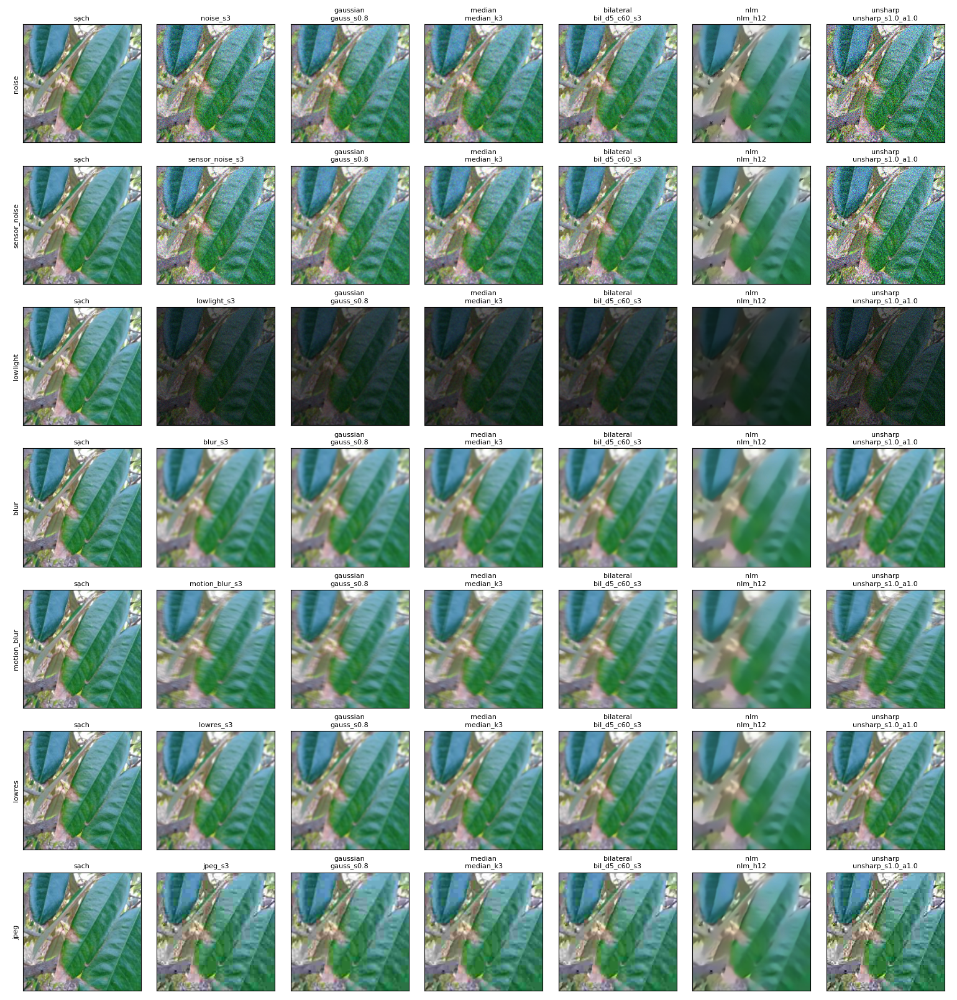

In [4]:
preview_choice = {"gaussian": "gauss_s0.8", "median": "median_k3", "bilateral": "bil_d5_c60_s3", "nlm": "nlm_h12", "unsharp": "unsharp_s1.0_a1.0"}
preview = {
    technique: {"per_family": {}, "general": {"config_id": config, "params": grid_cfg["techniques"][technique]["grid"][config]}}
    for technique, config in preview_choice.items()
}
diseased = int(np.where(cache.labels == classes.index("LEAF_BLIGHT"))[0][0])
for severity, index in [(2, 0), (3, diseased)]:
    path = FIG / f"preview_s{severity}_img{index}.png"
    plot_corruption_examples(example_grid(cache, preview, index, severity, families), path, dpi=100)
    print(f"Ảnh {index} ({classes[int(cache.labels[index])]}), mức {severity}")
    show(path)

## 4. Baseline không xử lý

Macro F1 của reference model trên ảnh sạch và 21 điều kiện. Cột `lệch 4.1` so với bảng hiệu chỉnh ở task 4.1 (làm tròn 3 chữ số). Lệch dưới 0,001 là khớp.

In [5]:
runner.raw()
frame = runner.frame()
raw = frame[frame["role"] == "raw"]
clean_f1 = float(raw[raw["condition"] == "clean"]["macro_f1"].iloc[0])
print(f"Macro F1 ảnh sạch: {clean_f1:.4f}")
raw_table = raw[raw["condition"] != "clean"].pivot(index="family", columns="severity", values="macro_f1").reindex(families)

recorded_41 = {
    "noise": [0.957, 0.849, 0.622], "sensor_noise": [0.926, 0.848, 0.750], "lowlight": [0.904, 0.826, 0.637],
    "blur": [0.948, 0.698, 0.577], "motion_blur": [0.909, 0.768, 0.635], "lowres": [0.768, 0.692, 0.636],
    "jpeg": [0.896, 0.885, 0.711],
}
diff = pd.DataFrame({family: np.round(raw_table.loc[family].values, 3) - np.array(values) for family, values in recorded_41.items()}, index=[1, 2, 3]).T
display(raw_table.round(3).assign(**{"lệch 4.1 lớn nhất": diff.abs().max(axis=1).round(4)}))
if diff.abs().max().max() > 0.002:
    print("CẢNH BÁO: có điểm lệch hơn 0,002 so với bảng 4.1 trong reports/corruptions/README.md.")

Macro F1 ảnh sạch: 0.9775


severity,1,2,3,lệch 4.1 lớn nhất
family,,,,
noise,0.957,0.849,0.622,0.0
sensor_noise,0.926,0.848,0.750,0.0
lowlight,0.904,0.826,0.637,0.0
blur,0.948,0.698,0.577,0.0
motion_blur,0.909,0.768,0.635,0.0
lowres,0.768,0.692,0.636,0.0
jpeg,0.896,0.885,0.711,0.0


## 5. Tối ưu tham số trên validation

Mỗi kỹ thuật chạy toàn bộ lưới tham số trên các họ suy giảm phù hợp với nó (xem `configs/restoration.yaml`). Ô này chạy lâu nhất, khoảng 15 đến 30 phút trên T4 (NLM là phần chậm nhất). Log in mỗi cấu hình khi xong.

In [6]:
start = time.time()
run_tuning(runner, grid_cfg)
print(f"Tối ưu xong sau {(time.time() - start) / 60:.1f} phút")
run_clean_cost(runner, grid_cfg)
frame = runner.frame()
frame.to_csv(RES / "restoration_grid.csv", index=False)
print(f"{len(frame)} dòng kết quả, đã lưu {RES / 'restoration_grid.csv'}")

gaussian   gauss_s0.3       đã chạy 9 điều kiện
gaussian   gauss_s0.5       đã chạy 9 điều kiện
gaussian   gauss_s0.8       đã chạy 9 điều kiện
gaussian   gauss_s1.2       đã chạy 9 điều kiện
gaussian   gauss_s1.8       đã chạy 9 điều kiện
median     median_k3        đã chạy 9 điều kiện
median     median_k5        đã chạy 9 điều kiện
bilateral  bil_d5_c10_s3    đã chạy 9 điều kiện
bilateral  bil_d7_c10_s5    đã chạy 9 điều kiện
bilateral  bil_d7_c20_s5    đã chạy 9 điều kiện
bilateral  bil_d5_c30_s3    đã chạy 9 điều kiện
bilateral  bil_d5_c60_s3    đã chạy 9 điều kiện
bilateral  bil_d7_c30_s5    đã chạy 9 điều kiện
bilateral  bil_d7_c60_s5    đã chạy 9 điều kiện
nlm        nlm_h1.5         đã chạy 9 điều kiện
nlm        nlm_h3           đã chạy 9 điều kiện
nlm        nlm_h5           đã chạy 9 điều kiện
nlm        nlm_h12          đã chạy 9 điều kiện
nlm        nlm_h20          đã chạy 9 điều kiện
unsharp    unsharp_s1.0_a0.5 đã chạy 9 điều kiện
unsharp    unsharp_s1.0_a1.0 đã chạy 9 

### Kết quả lưới tham số

Mỗi ô nhỏ là một họ suy giảm. Trục ngang là cấu hình, ba cột màu là ba mức. Đường đứt cùng màu là điểm khi không xử lý, nên cột nào vượt đường đứt cùng màu là cấu hình đó giúp được. Đường chấm xám là điểm ảnh sạch, tức mức tối đa có thể phục hồi.

== gaussian


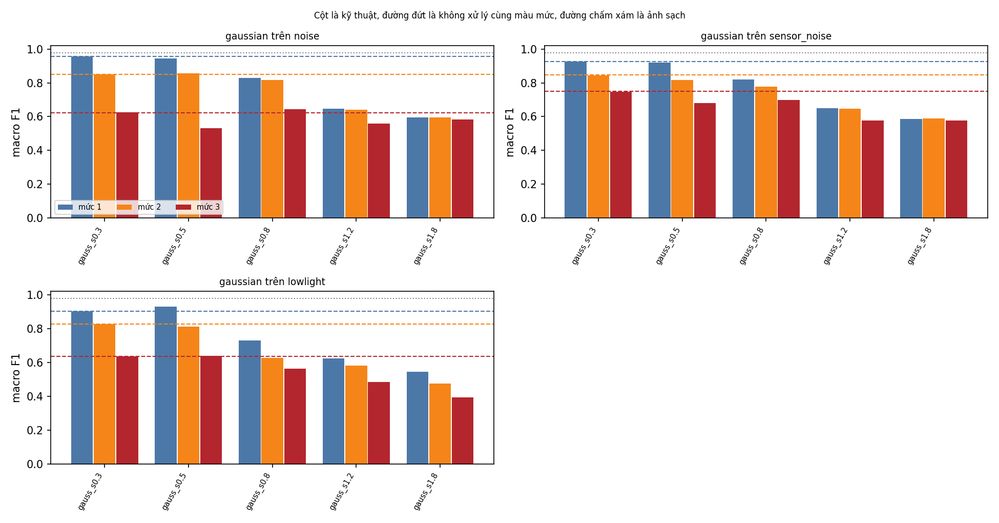

== median


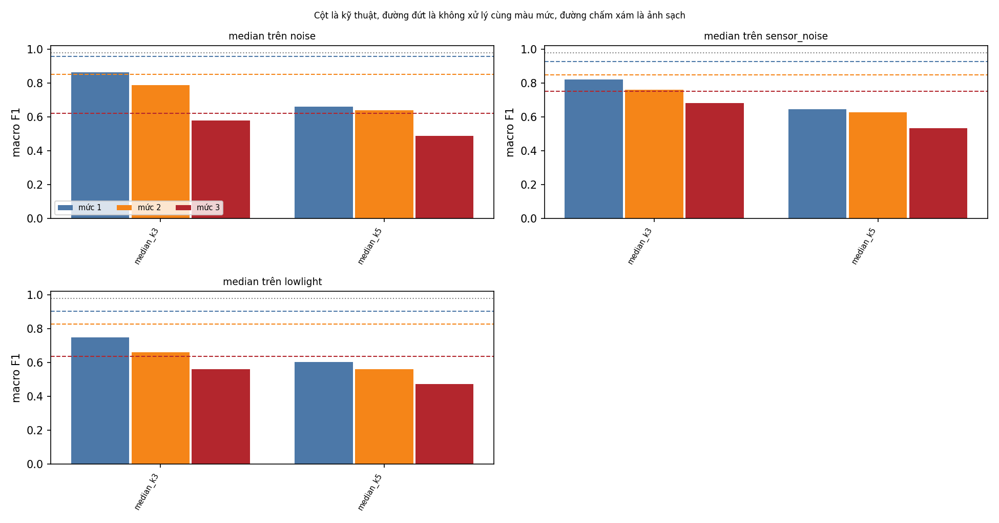

== bilateral


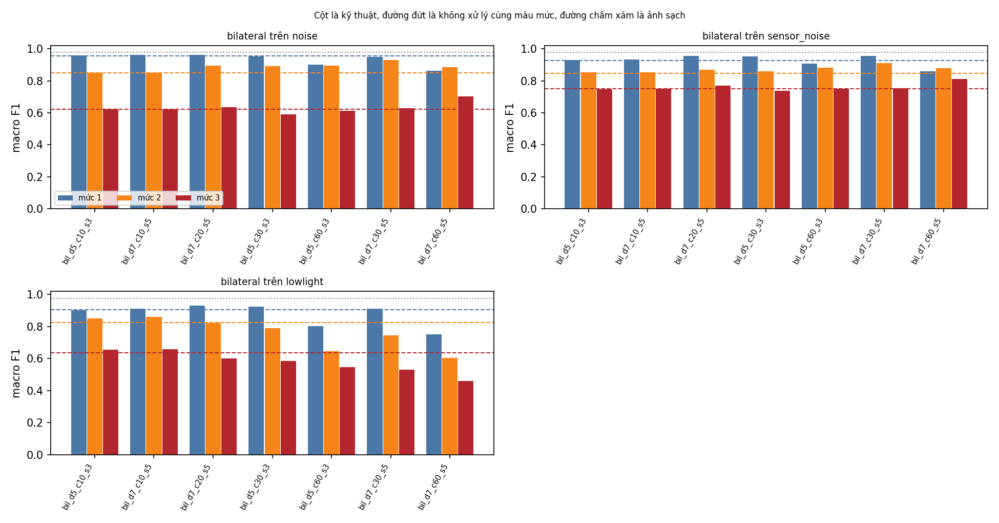

== nlm


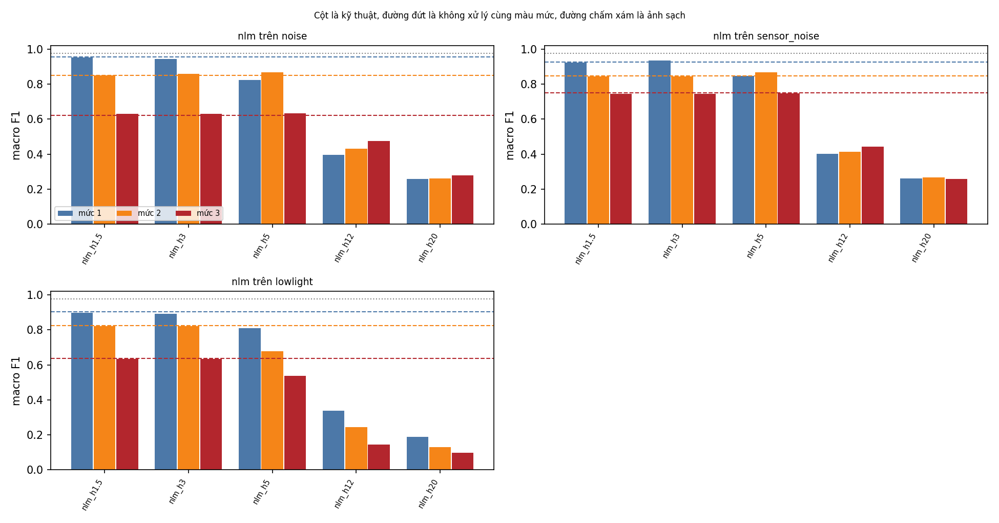

== unsharp


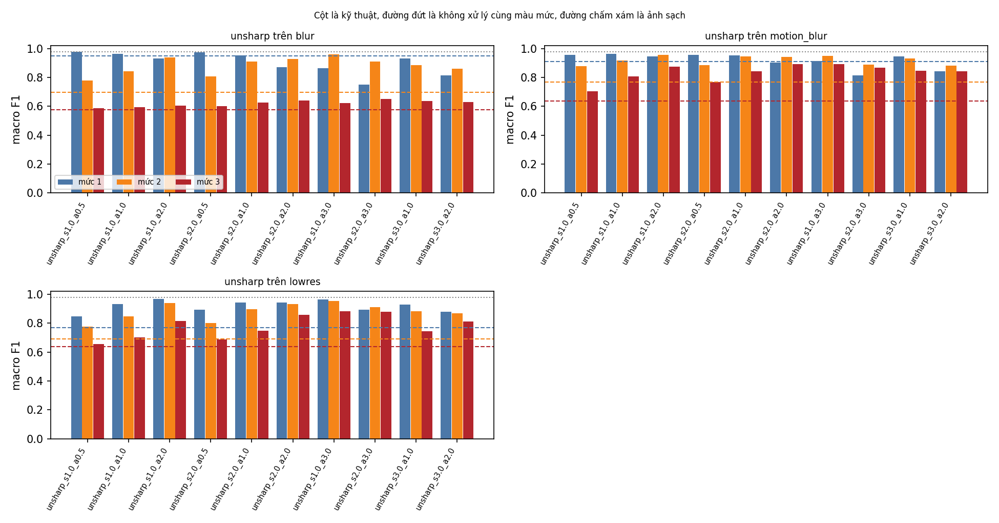

In [7]:
for technique, spec in grid_cfg["techniques"].items():
    path = FIG / f"grid_{technique}.png"
    plot_grid_search(frame, technique, spec["families"], list(spec["grid"]), path)
    print(f"== {technique}")
    show(path)

## 6. Chọn cấu hình tham số

Với mỗi cặp kỹ thuật và họ phù hợp, chọn cấu hình có macro F1 trung bình trên ba mức cao nhất. Nếu có cấu hình trong khoảng 0,003 so với cấu hình tốt nhất thì lấy cấu hình giữ F1 ảnh sạch cao hơn. Mỗi kỹ thuật còn một cấu hình chung (điểm trung bình cao nhất qua mọi họ phù hợp), dùng làm "kỹ thuật cố định" và cho đối chứng không phù hợp.

In [8]:
selected = select_configs(frame, grid_cfg)
raw_mean = raw[raw["condition"] != "clean"].groupby("family")["macro_f1"].mean()
summary = pd.DataFrame(
    [
        {"kỹ thuật": technique, "họ": family, "cấu hình": item["config_id"], "F1 sau xử lý": item["mean_macro_f1"],
         "F1 không xử lý": raw_mean[family], "tăng": item["mean_macro_f1"] - raw_mean[family]}
        for technique, entry in selected.items() for family, item in entry["per_family"].items()
    ]
)
display(summary.round(4))
general = pd.DataFrame(
    [{"kỹ thuật": technique, "cấu hình chung": entry["general"]["config_id"], "F1 trung bình họ phù hợp": entry["general"]["mean_macro_f1"],
      "F1 ảnh sạch sau xử lý": entry["general"]["clean_macro_f1"], "F1 ảnh sạch gốc": clean_f1} for technique, entry in selected.items()]
)
display(general.round(4))

,kỹ thuật,họ,cấu hình,F1 sau xử lý,F1 không xử lý,tăng
0,gaussian,noise,gauss_s0.3,0.8107,0.8093,0.0014
1,gaussian,sensor_noise,gauss_s0.3,0.8393,0.8413,-0.0019
2,gaussian,lowlight,gauss_s0.5,0.7937,0.7889,0.0048
3,median,noise,median_k3,0.7419,0.8093,-0.0674
4,median,sensor_noise,median_k3,0.7536,0.8413,-0.0877
5,median,lowlight,median_k3,0.6556,0.7889,-0.1332
6,bilateral,noise,bil_d7_c30_s5,0.8365,0.8093,0.0272
7,bilateral,sensor_noise,bil_d7_c30_s5,0.8742,0.8413,0.0329
8,bilateral,lowlight,bil_d7_c10_s5,0.8113,0.7889,0.0224
9,nlm,noise,nlm_h1.5,0.8100,0.8093,0.0007


,kỹ thuật,cấu hình chung,F1 trung bình họ phù hợp,F1 ảnh sạch sau xử lý,F1 ảnh sạch gốc
0,gaussian,gauss_s0.3,0.8129,0.9775,0.9775
1,median,median_k3,0.7170,0.8600,0.9775
2,bilateral,bil_d7_c20_s5,0.8268,0.9589,0.9775
3,nlm,nlm_h1.5,0.8106,0.9771,0.9775
4,unsharp,unsharp_s1.0_a3.0,0.8890,0.7429,0.9775


## 7. Đối chứng không phù hợp và bản đồ phục hồi

Cấu hình chung của mỗi kỹ thuật chạy thêm trên các họ không phù hợp với nó, để thấy kỹ thuật nào làm hại ở đâu. Rồi ghép thành bảng kỹ thuật × 21 điều kiện.

Chỉ số: `recovery` = F1 sau xử lý trừ F1 suy giảm. `normalized recovery` = recovery chia mức giảm (F1 sạch trừ F1 suy giảm), chỉ tính khi mức giảm lớn hơn 0,02. Gần 1 là lấy lại gần hết phần đã mất, 0 là không đổi, âm là xử lý làm tệ hơn.

In [9]:
run_controls(runner, grid_cfg, selected)
frame = runner.frame()
matrix = build_matrix(frame, selected, float(grid_cfg["selection"]["min_degradation"]))
matrix.to_csv(RES / "restoration_matrix.csv", index=False)
print(f"{len(matrix)} ô trong bản đồ phục hồi ({matrix['suitable'].sum()} cặp phù hợp, {(~matrix['suitable']).sum()} cặp đối chứng)")

gaussian   đối chứng không phù hợp xong
median     đối chứng không phù hợp xong
bilateral  đối chứng không phù hợp xong
nlm        đối chứng không phù hợp xong
unsharp    đối chứng không phù hợp xong
105 ô trong bản đồ phục hồi (45 cặp phù hợp, 60 cặp đối chứng)


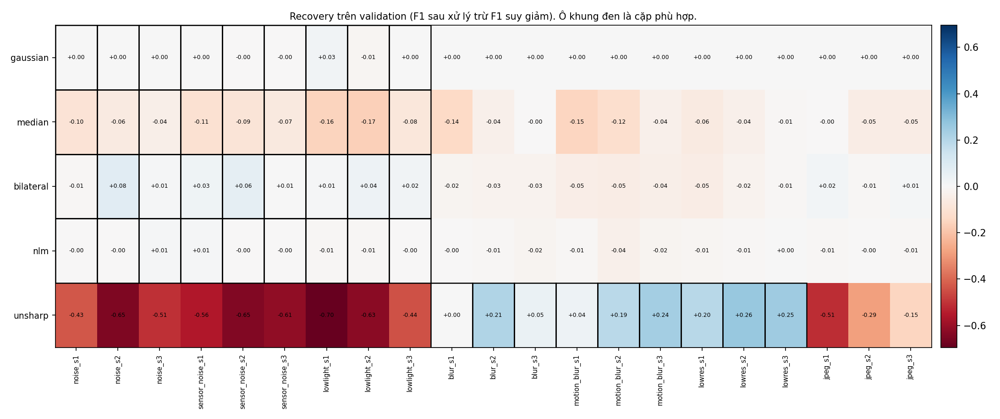

In [10]:
plot_matrix_heatmap(matrix, "recovery", families, FIG / "recovery_heatmap.png", "Recovery trên validation (F1 sau xử lý trừ F1 suy giảm). Ô khung đen là cặp phù hợp.")
show(FIG / "recovery_heatmap.png")

Cách đọc: xanh là xử lý giúp, đỏ là làm hại. Ô có khung đen là cặp kỹ thuật và họ phù hợp, ô không khung là đối chứng. Một kỹ thuật tốt là xanh trong khung đen, và không đỏ đậm ngoài khung.

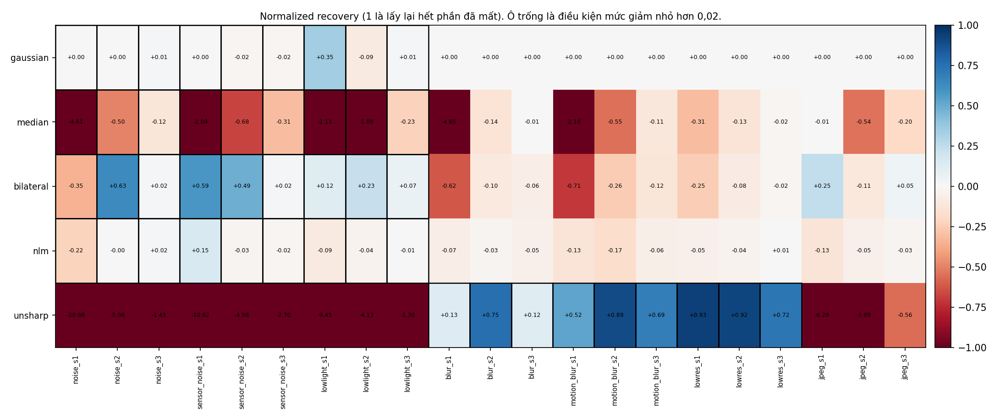

In [11]:
plot_matrix_heatmap(matrix, "normalized_recovery", families, FIG / "normalized_recovery_heatmap.png", "Normalized recovery (1 là lấy lại hết phần đã mất). Ô trống là điều kiện mức giảm nhỏ hơn 0,02.", limit=1.0)
show(FIG / "normalized_recovery_heatmap.png")

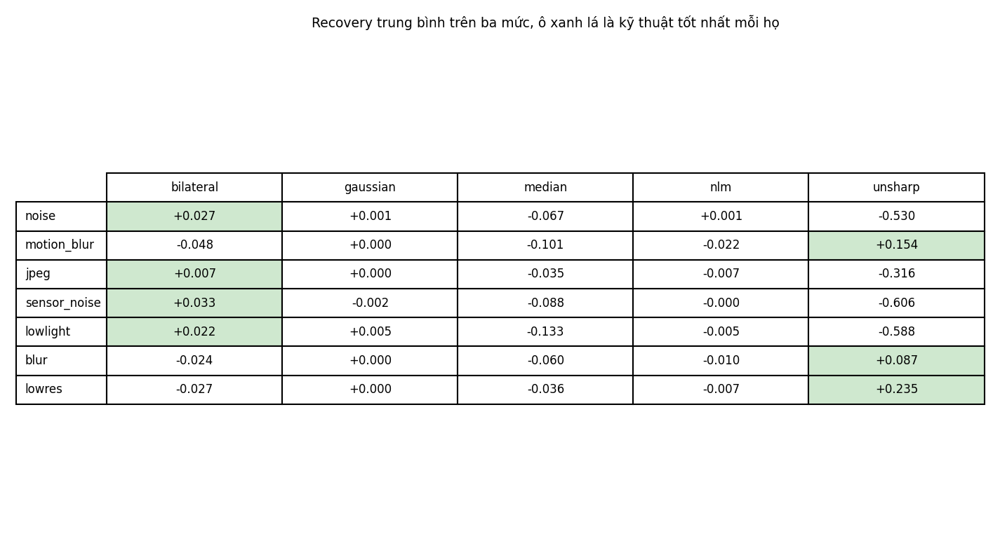

In [12]:
plot_rank_table(matrix, "recovery", FIG / "rank_recovery.png", "Recovery trung bình trên ba mức, ô xanh lá là kỹ thuật tốt nhất mỗi họ")
show(FIG / "rank_recovery.png")

## 8. Kỹ thuật tốt nhất mỗi điều kiện

Với mỗi điều kiện, kỹ thuật cho macro F1 cao nhất trên validation (kể cả cặp không phù hợp). Đây chỉ để quan sát. Kết luận sạch phải đo lại trên test ở task 4.5, vì chọn kỹ thuật tốt nhất trên cùng tập đo sẽ lạc quan.

,family,severity,technique,config_id,raw_macro_f1,macro_f1,recovery,normalized_recovery
condition,,,,,,,,
noise_s2,noise,2,bilateral,bil_d7_c30_s5,0.849,0.931,0.081,0.635
motion_blur_s3,motion_blur,3,unsharp,unsharp_s1.0_a2.0,0.635,0.873,0.238,0.694
jpeg_s1,jpeg,1,bilateral,bil_d7_c20_s5,0.896,0.916,0.020,0.247
noise_s1,noise,1,gaussian,gauss_s0.3,0.957,0.957,0.000,0.000
noise_s3,noise,3,nlm,nlm_h1.5,0.622,0.629,0.007,0.021
sensor_noise_s1,sensor_noise,1,bilateral,bil_d7_c30_s5,0.926,0.956,0.030,0.586
sensor_noise_s2,sensor_noise,2,bilateral,bil_d7_c30_s5,0.848,0.911,0.063,0.488
sensor_noise_s3,sensor_noise,3,bilateral,bil_d7_c30_s5,0.750,0.755,0.005,0.023
lowlight_s1,lowlight,1,gaussian,gauss_s0.5,0.904,0.930,0.026,0.349


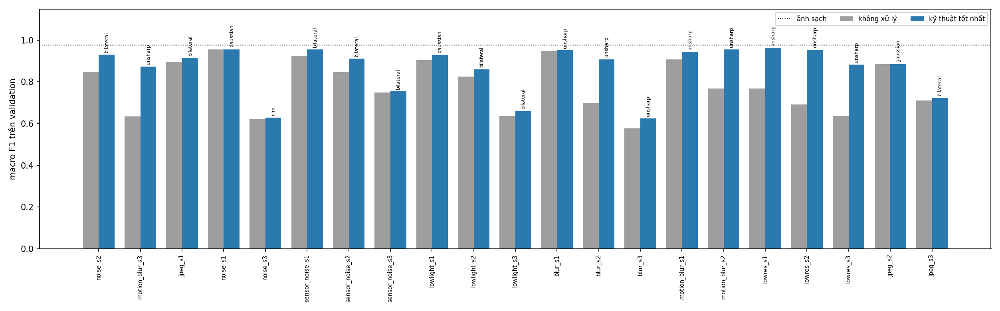

In [13]:
best = best_per_condition(matrix)
best.to_csv(RES / "restoration_best_per_condition.csv")
display(best.round(3))
plot_best_per_condition(best, clean_f1, FIG / "best_per_condition.png")
show(FIG / "best_per_condition.png")

### Ảnh minh họa với cấu hình đã chọn

Cùng bố cục với mục 3 nhưng dùng cấu hình đã chọn cho từng họ. Cột sau cột "suy giảm" là các kỹ thuật theo thứ tự gaussian, median, bilateral, nlm, unsharp.

Ảnh 0 (ALGAL_LEAF_SPOT), mức 2


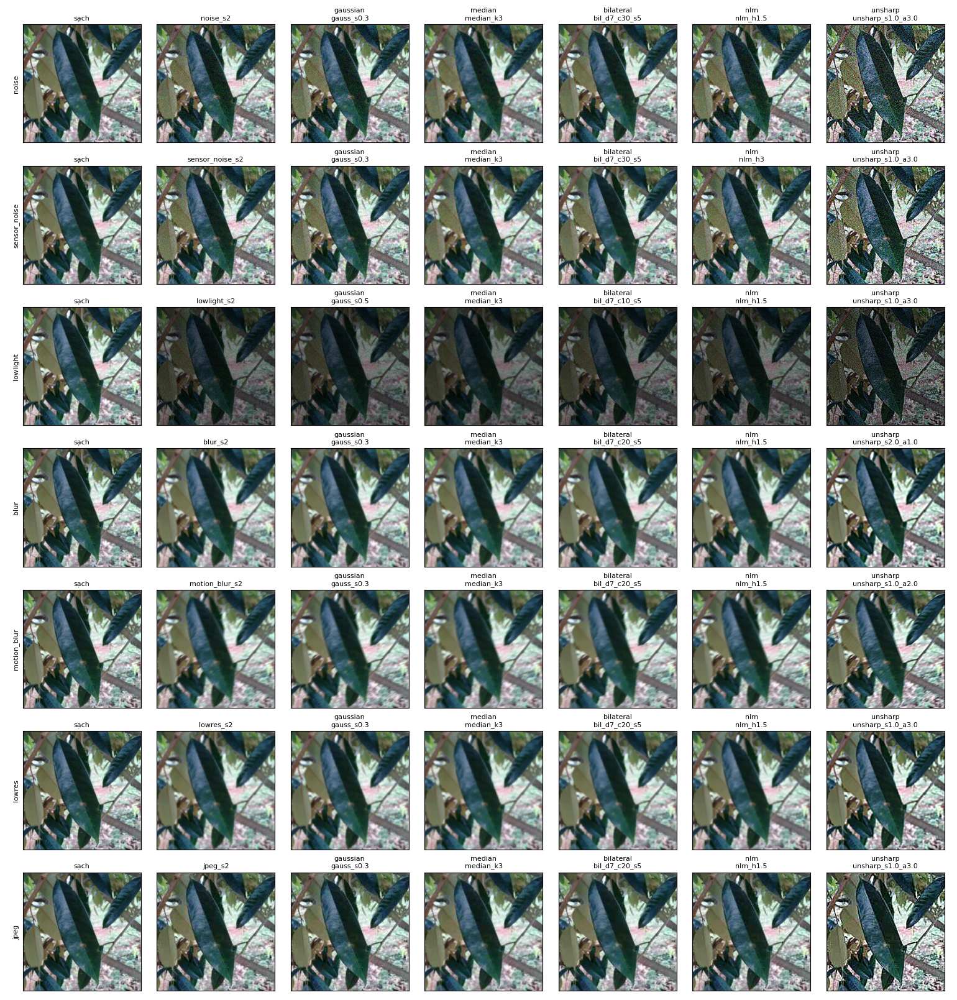

Ảnh 57 (LEAF_BLIGHT), mức 3


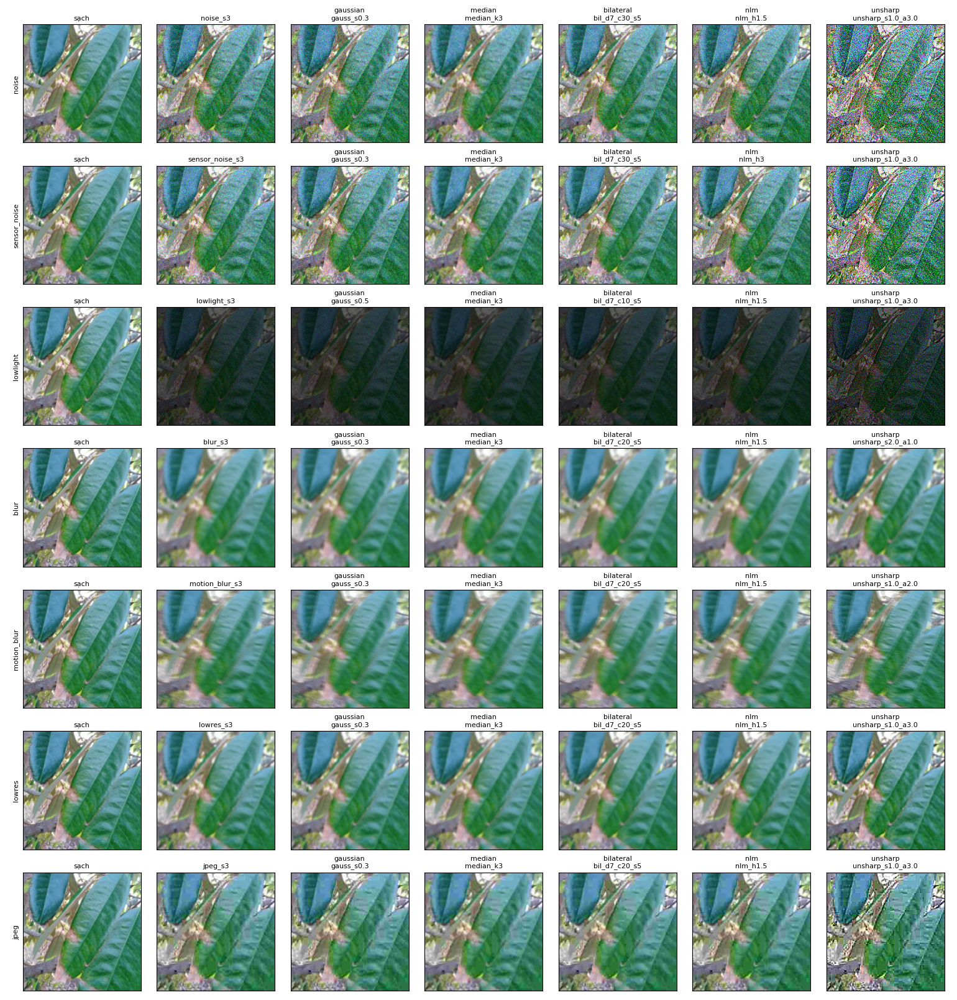

Ảnh 38 (HEALTHY_LEAF), mức 3


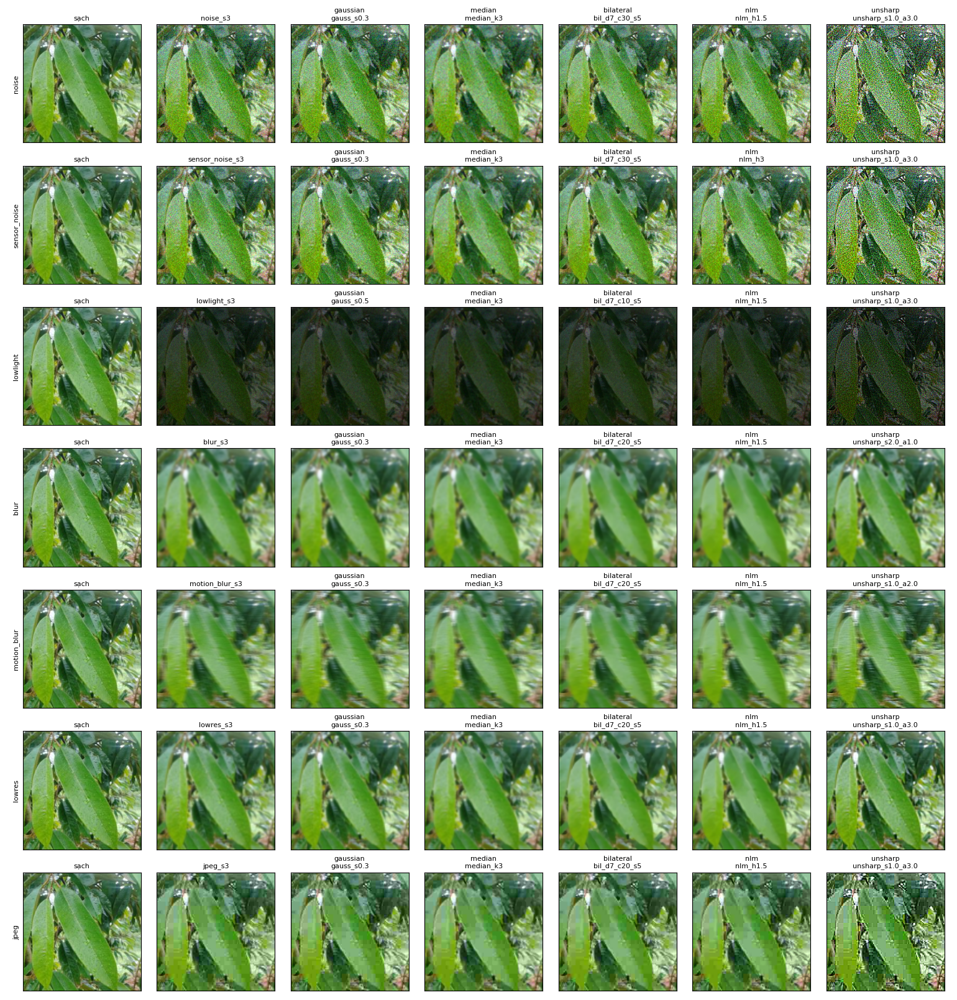

In [14]:
for severity, index in [(2, 0), (3, diseased), (3, int(np.where(cache.labels == classes.index("HEALTHY_LEAF"))[0][0]))]:
    path = FIG / f"selected_s{severity}_img{index}.png"
    plot_corruption_examples(example_grid(cache, selected, index, severity, families), path, dpi=100)
    print(f"Ảnh {index} ({classes[int(cache.labels[index])]}), mức {severity}")
    show(path)

## 9. Chi phí trên ảnh sạch

Khi ảnh không hỏng mà vẫn bị xử lý thì điểm đổi bao nhiêu. Bên trái là thay đổi macro F1 tổng, bên phải là thay đổi recall từng lớp. Một kỹ thuật làm giảm mạnh một lớp bệnh là dấu hiệu xử lý xóa mất đặc trưng của lớp đó.

,technique,config_id,macro_f1,change_macro_f1
0,gaussian,gauss_s0.3,0.9775,0.0000
1,median,median_k3,0.8600,-0.1174
2,bilateral,bil_d7_c20_s5,0.9589,-0.0185
3,nlm,nlm_h1.5,0.9771,-0.0003
4,unsharp,unsharp_s1.0_a3.0,0.7429,-0.2346


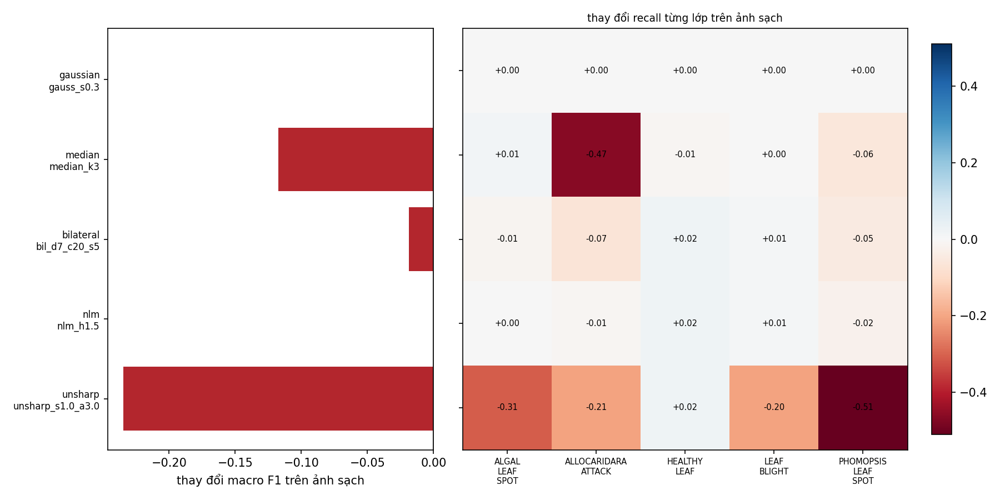

In [15]:
cost = clean_cost_table(frame, selected)
cost.to_csv(RES / "restoration_clean_cost.csv", index=False)
display(cost[["technique", "config_id", "macro_f1", "change_macro_f1"]].round(4))
plot_clean_cost(cost, classes, FIG / "clean_cost.png")
show(FIG / "clean_cost.png")

## 10. Phân tích ca điển hình

Confusion matrix của hai điều kiện được phục hồi nhiều nhất và hai điều kiện bị làm tệ nhất. Mỗi cặp: trái là không xử lý, phải là sau xử lý.

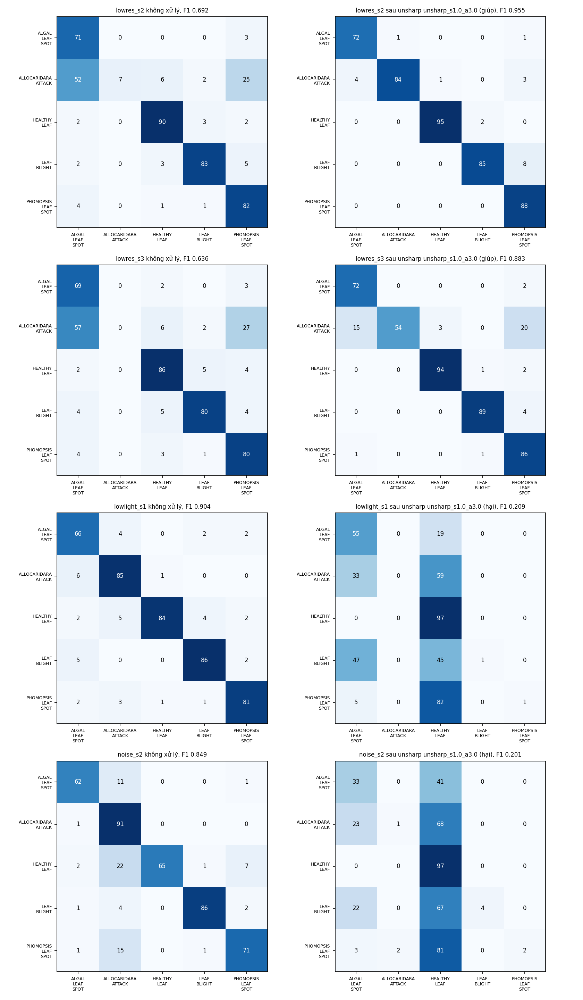

In [16]:
from sklearn.metrics import confusion_matrix

def matrix_of(technique, config_id, condition):
    preds = runner.predictions[f"{technique}|{config_id}|{condition}"].astype(int)
    return confusion_matrix(cache.labels, preds, labels=list(range(len(classes)))).tolist()

picked = pd.concat([matrix.nlargest(2, "recovery"), matrix.nsmallest(2, "recovery")])
cases = []
for row in picked.itertuples():
    tag = "giúp" if row.recovery > 0 else "hại"
    cases.append((f"{row.condition} không xử lý, F1 {row.raw_macro_f1:.3f}", matrix_of("none", "none", row.condition)))
    cases.append((f"{row.condition} sau {row.technique} {row.config_id} ({tag}), F1 {row.macro_f1:.3f}", matrix_of(row.technique, row.config_id, row.condition)))
plot_confusion_cases(cases, classes, FIG / "confusion_cases.png")
show(FIG / "confusion_cases.png")

## 11. Độ sắc nét trước và sau xử lý

Khử nhiễu dễ làm mờ vết bệnh, làm nét dễ khuếch đại nhiễu. Với bốn điều kiện mức 3, bảng dưới đo độ sắc nét trung bình (phương sai Laplacian của ảnh xám) ở ba trạng thái. Khử nhiễu tốt đưa độ sắc nét về gần ảnh sạch. Thấp hơn nhiều là mất chi tiết, cao hơn nhiều là còn nhiễu hoặc tạo artifact. Đây chỉ là số phụ, tiêu chí chính vẫn là macro F1.

In [17]:
from concurrent.futures import ThreadPoolExecutor


def sharpness(image):
    gray = cv2.cvtColor((image.permute(1, 2, 0).numpy() * 255).round().astype(np.uint8), cv2.COLOR_RGB2GRAY)
    return float(cv2.Laplacian(gray, cv2.CV_64F).var())


def mean_sharpness(images, processor=None):
    batch = list(images.float() / 255.0)
    with ThreadPoolExecutor(max_workers=WORKERS) as pool:
        if processor is not None:
            batch = list(pool.map(processor, batch))
        return float(np.mean(list(pool.map(sharpness, batch))))


clean_sharp = mean_sharpness(cache.get("clean"))
rows = []
for condition in ["noise_s3", "sensor_noise_s3", "blur_s3", "lowres_s3"]:
    entry = best.loc[condition]
    processor = make_processor(entry["technique"], dict(grid_cfg["techniques"][entry["technique"]]["grid"][entry["config_id"]]))
    rows.append({
        "điều kiện": condition, "kỹ thuật tốt nhất": f"{entry['technique']} {entry['config_id']}",
        "sạch": clean_sharp, "suy giảm": mean_sharpness(cache.get(condition)), "đã xử lý": mean_sharpness(cache.get(condition), processor),
    })
display(pd.DataFrame(rows).round(1))

,điều kiện,kỹ thuật tốt nhất,sạch,suy giảm,đã xử lý
0,noise_s3,nlm nlm_h1.5,544.5,6157.1,6178.0
1,sensor_noise_s3,bilateral bil_d7_c30_s5,544.5,5099.1,3336.2
2,blur_s3,unsharp unsharp_s2.0_a1.0,544.5,11.4,26.2
3,lowres_s3,unsharp unsharp_s1.0_a3.0,544.5,52.2,352.3


## 12. Lưu kết quả

Ghi file lưới tham số, bản đồ phục hồi, dự đoán từng ảnh (cho kiểm định ghép cặp ở 4.5) và cấu hình đã chọn. File cấu hình đã chọn nằm ở `reports/processing/restoration_selected.json`, đây là file task 4.5 và Phase 5 đọc.

In [18]:
import shutil
import zipfile

save_predictions(runner, RES / "restoration_predictions.npz")
record = {
    "task": "4.4",
    "split": "val",
    "reference_model": reference,
    "corruption_config": grid_cfg["corruption_config"],
    "grid_config_version": grid_cfg["version"],
    "clean_macro_f1": clean_f1,
    "selection_rule": grid_cfg["selection"],
    "selected": selected,
    "clean_cost": cost.to_dict(orient="records"),
    "note": "Tham số chọn trên validation. Tập test chưa mở. Task 4.5 đo bản đồ phục hồi trên test với đúng các cấu hình này.",
}
(REP / "restoration_selected.json").write_text(json.dumps(record, indent=2, ensure_ascii=False), encoding="utf-8")
for name in ["recovery_heatmap", "normalized_recovery_heatmap", "rank_recovery", "best_per_condition", "clean_cost", "confusion_cases"]:
    shutil.copy(FIG / f"{name}.png", REP / f"restoration_{name}.png")
for path in FIG.glob("selected_s*.png"):
    shutil.copy(path, REP / f"restoration_{path.name}")
for name in ["restoration_matrix.csv", "restoration_best_per_condition.csv", "restoration_clean_cost.csv"]:
    shutil.copy(RES / name, REP / name)

archive = Path("/kaggle/working/restoration_outputs.zip")
with zipfile.ZipFile(archive, "w", zipfile.ZIP_DEFLATED) as bundle:
    for folder in (RES, FIG, REP):
        for path in sorted(folder.rglob("*")):
            if path.is_file():
                bundle.write(path, path.relative_to(REPO_DIR).as_posix())
print(f"Đã nén {archive} ({archive.stat().st_size / 1024**2:.1f} MB)")
print()
print("Quan sát trước: bản đồ phục hồi (recovery_heatmap.png), chi phí ảnh sạch (clean_cost.png), file restoration_selected.json.")

Đã nén /kaggle/working/restoration_outputs.zip (28.5 MB)

Quan sát trước: bản đồ phục hồi (recovery_heatmap.png), chi phí ảnh sạch (clean_cost.png), file restoration_selected.json.
